# 02 · Text Preprocessing
**Project:** Tweet Emotion Detection · **Input:** raw CSVs in `data/` · **Output:** `data/processed/`

**Goal.** Turn noisy raw tweets into clean, consistent tokens **without throwing away emotion signals**.
Every step below is justified by a finding from `01_eda.ipynb` (referenced as *EDA Q#*).

**Scope.** Only preprocessing. Turning tokens into numbers (BoW, TF-IDF, embeddings) is the next notebook, `03_representation`.

### Pipeline

| Step | Operation | Why (EDA evidence) |
|---|---|---|
| 1 | Remove duplicate tweets (train only) | 25 spam copies of one joy tweet (Q2) |
| 2 | Fix encoding noise: literal `\n`, HTML entities, Unicode, curly quotes, invisible characters | 279 `\n`, 240 `&amp;`, 43 `’` (Q2) |
| 3 | Remove `@user` mentions and URLs | `@user` in 44% of tweets, carries no meaning (Q5) |
| 4 | Hashtags: drop `#`, keep and split the word | Hashtags often name the emotion (`#angry`, `#sad`) (Q6) |
| 5 | Emojis → one word-token each (😭 → `loudly_crying_face`) | Emojis differ strongly by emotion (😡 vs 😭) (Q5–Q6) |
| 6 | Lowercase + expand contractions | Unify word forms; make negation explicit (`can't` → `can not`) (Q9) |
| 7 | Tokenize with `TweetTokenizer` (also shortens `sooo` → `soo`) | Tweet-aware tokenizer (Q5) |
| 8 | Remove punctuation and numbers, **keep `!` and `?`** | `!` is typical of joy, `?` of anger (Q5) |
| 9 | Stop-word removal **without negations** *(variant)* | Negation in 26% of tweets (Q9) |
| 10 | Lemmatization with POS tags *(variant)* | Merge word forms (*crying, cried* → *cry*) |


## Setup

In [1]:
import os, re, html, unicodedata, warnings
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
import nltk
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer, PorterStemmer

for resource in ["stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

DATA_DIR, OUT_DIR, FIG_DIR = "../data", "../data/processed", "../results/figures/preprocessing"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
LABELS = ["anger", "joy", "optimism", "sadness"]
PARTS = ["train", "validation", "test"]

## Load the raw data

In [2]:
raw = {}
for p in PARTS:
    d = pd.read_csv(f"{DATA_DIR}/{p}.csv")
    d["text"] = d["text"].astype(object)          # plain Python strings (works with any pandas version)
    d["emotion"] = d["label"].map(dict(enumerate(LABELS)))
    raw[p] = d
{p: len(d) for p, d in raw.items()}

{'train': 3257, 'validation': 374, 'test': 1421}

## Step 1 · Remove duplicate tweets

In [3]:
before = len(raw["train"])
raw["train"] = raw["train"].drop_duplicates("text").reset_index(drop=True)
print(f"train: {before} → {len(raw['train'])} tweets ({before - len(raw['train'])} duplicates removed)")

train: 3257 → 3232 tweets (25 duplicates removed)


## Steps 2–8 · Cleaning functions


In [4]:
INVISIBLE_RE = re.compile("[\u200b-\u200f\u2060\ufeff\ufe0e\ufe0f]")   # zero-width chars, variation selectors
SKIN_TONE_RE = re.compile("[\U0001F3FB-\U0001F3FF]")                        # emoji skin-tone modifiers

def fix_encoding(t):
    """Step 2: literal '\\n', HTML entities, Unicode form, curly quotes, invisible characters."""
    t = t.replace("\\n", " ")                       # literal backslash + n left by scraping
    t = html.unescape(t)                             # &amp; → &, &lt; → <
    t = unicodedata.normalize("NFC", t)              # one canonical form per character
    t = t.translate(str.maketrans({"’": "'", "‘": "'", "“": '"', "”": '"'}))
    t = INVISIBLE_RE.sub("", t)
    return t

def remove_mentions_urls(t):
    """Step 3: '@user' and links carry no emotion."""
    t = re.sub(r"@\w+", " ", t)
    return re.sub(r"https?://\S+|www\.\S+", " ", t)

def split_hashtag(m):
    word = m.group(1)
    return " " + re.sub(r"(?<=[a-z])(?=[A-Z])", " ", word) + " "   # camelCase split: #BadDay → Bad Day

def process_hashtags(t):
    """Step 4: '#angry' → 'angry', '#BadDay' → 'Bad Day'."""
    return re.sub(r"#(\w+)", split_hashtag, t)

def emojis_to_words(t):
    """Step 5: '😭' → one token 'loudly_crying_face' (keeps the emoji's own meaning)."""
    t = SKIN_TONE_RE.sub("", t)
    t = emoji.demojize(t, delimiters=(" <e>", "</e> "))
    return re.sub(r"<e>(.*?)</e>", lambda m: re.sub(r"[^a-z]+", "_", m.group(1).lower()).strip("_"), t)

CONTRACTIONS = {
    r"\bwon't\b": "will not", r"\bcan't\b": "can not", r"\bain't\b": "is not", r"\bshan't\b": "shall not",
    r"n't\b": " not", r"'re\b": " are", r"'ve\b": " have", r"'ll\b": " will", r"'d\b": " would", r"'m\b": " am",
}
def lowercase_expand(t):
    """Step 6: lowercase and expand contractions, so negation becomes an explicit 'not'."""
    t = t.lower()
    for pat, rep in CONTRACTIONS.items():
        t = re.sub(pat, rep, t)
    return t

TOKENIZER = TweetTokenizer(preserve_case=True, reduce_len=True)   # reduce_len: 'sooooo' → 'sooo'
def tokenize(t):
    """Step 7."""
    return TOKENIZER.tokenize(t)

KEEP_PUNCT = {"!", "?"}
def filter_tokens(tokens):
    """Step 8: keep words (letters; may contain ' or _ as in emoji tokens) plus '!' and '?'."""
    out = []
    for tok in tokens:
        if set(tok) <= KEEP_PUNCT:                        # '!!!' → '!'
            out.append(tok[0])
        elif re.fullmatch(r"[a-z]+(?:['_][a-z]+)*", tok):
            out.append(tok)
    return out

def clean(t):
    """Steps 2–8 → list of tokens."""
    for f in [fix_encoding, remove_mentions_urls, process_hashtags, emojis_to_words, lowercase_expand]:
        t = f(t)
    return filter_tokens(tokenize(t))

### Step-by-step trace on real tweets data

In [5]:
def trace(t):
    steps = [("raw", t)]
    for name, f in [("2 fix_encoding", fix_encoding), ("3 remove_mentions_urls", remove_mentions_urls),
                    ("4 process_hashtags", process_hashtags), ("5 emojis_to_words", emojis_to_words),
                    ("6 lowercase_expand", lowercase_expand)]:
        t = f(t); steps.append((name, t))
    toks = tokenize(t); steps.append(("7 tokenize", toks))
    steps.append(("8 filter_tokens", filter_tokens(toks)))
    return pd.DataFrame(steps, columns=["step", "result"]).set_index("step")

all_raw = pd.concat(raw.values(), ignore_index=True)
examples = [
    all_raw[all_raw.text.str.contains("\\n", regex=False) & all_raw.text.str.contains("&amp;", regex=False)].text.iloc[0],
    all_raw[all_raw.text.str.contains("😭") & all_raw.text.str.contains("#")].text.iloc[0],
    all_raw[all_raw.text.str.contains("n't") & all_raw.text.str.contains("@user")].text.iloc[0],
]
for ex in examples:
    display(trace(ex))

,result
step,
raw,#FF \n\n@The_Family_X \n\n#soul #blues &amp; #rock #band\n\n#music from the #heart\n\nWith soul &amp; #passion \n\nXx 🎶 xX
2 fix_encoding,#FF @The_Family_X #soul #blues & #rock #band #music from the #heart With soul & #passion Xx 🎶 xX
3 remove_mentions_urls,#FF #soul #blues & #rock #band #music from the #heart With soul & #passion Xx 🎶 xX
4 process_hashtags,FF soul blues & rock band music from the heart With soul & passion Xx 🎶 xX
5 emojis_to_words,FF soul blues & rock band music from the heart With soul & passion Xx musical_notes xX
6 lowercase_expand,ff soul blues & rock band music from the heart with soul & passion xx musical_notes xx
7 tokenize,"[ff, soul, blues, &, rock, band, music, from, the, heart, with, soul, &, passion, xx, musical_notes, xx]"
8 filter_tokens,"[ff, soul, blues, rock, band, music, from, the, heart, with, soul, passion, xx, musical_notes, xx]"


,result
step,
raw,Back in Cardiff after an amazing 10 days away 😭 #depressing
2 fix_encoding,Back in Cardiff after an amazing 10 days away 😭 #depressing
3 remove_mentions_urls,Back in Cardiff after an amazing 10 days away 😭 #depressing
4 process_hashtags,Back in Cardiff after an amazing 10 days away 😭 depressing
5 emojis_to_words,Back in Cardiff after an amazing 10 days away loudly_crying_face depressing
6 lowercase_expand,back in cardiff after an amazing 10 days away loudly_crying_face depressing
7 tokenize,"[back, in, cardiff, after, an, amazing, 10, days, away, loudly_crying_face, depressing]"
8 filter_tokens,"[back, in, cardiff, after, an, amazing, days, away, loudly_crying_face, depressing]"


,result
step,
raw,@user I would never strategically vote for someone I don't agree with. A lot of the Clinton vote based on fear and negativity.
2 fix_encoding,@user I would never strategically vote for someone I don't agree with. A lot of the Clinton vote based on fear and negativity.
3 remove_mentions_urls,I would never strategically vote for someone I don't agree with. A lot of the Clinton vote based on fear and negativity.
4 process_hashtags,I would never strategically vote for someone I don't agree with. A lot of the Clinton vote based on fear and negativity.
5 emojis_to_words,I would never strategically vote for someone I don't agree with. A lot of the Clinton vote based on fear and negativity.
6 lowercase_expand,i would never strategically vote for someone i do not agree with. a lot of the clinton vote based on fear and negativity.
7 tokenize,"[i, would, never, strategically, vote, for, someone, i, do, not, agree, with, ., a, lot, of, the, clinton, vote, based, on, fear, and, negativity, .]"
8 filter_tokens,"[i, would, never, strategically, vote, for, someone, i, do, not, agree, with, a, lot, of, the, clinton, vote, based, on, fear, and, negativity]"


## Steps 9–10 · Stop words and lemmatization (variants)

**Stop words.** We start from NLTK's English list but **keep negations** (*not, no, never, nor, ...*). The default list would delete them,
which can flip the emotion (*"not happy"* → *"happy"*). We also keep pronouns like *i* and *me*: EDA Q8 showed that *i* is characteristic of sadness.

**Lemmatization vs. stemming.** Stemming cuts word endings with rules and often produces non-words; lemmatization returns the dictionary form.
We use **WordNet lemmatization with POS tags**, because without a POS tag every word is treated as a noun (*crying* would stay *crying*).

In [6]:
NEGATIONS = {"not", "no", "nor", "never", "none", "nothing", "nobody", "neither", "nowhere", "cannot", "without"}
PRONOUNS = {"i", "me", "my", "myself", "you", "your", "we", "us", "our"}
STOP_WORDS = set(stopwords.words("english")) - NEGATIONS - PRONOUNS
STOP_WORDS |= {"amp", "rt", "via"}          # Twitter leftovers

def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOP_WORDS]

print(len(STOP_WORDS), "stop words, e.g.", sorted(STOP_WORDS)[:15])
print("Kept on purpose:", sorted(NEGATIONS | PRONOUNS))

190 stop words, e.g. ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'amp', 'an', 'and', 'any', 'are', 'aren']
Kept on purpose: ['cannot', 'i', 'me', 'my', 'myself', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'nowhere', 'our', 'us', 'we', 'without', 'you', 'your']


In [7]:
LEMMATIZER = WordNetLemmatizer()
POS_MAP = {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}

def lemmatize(tokens):
    tagged = nltk.pos_tag(tokens)
    return [LEMMATIZER.lemmatize(w, POS_MAP.get(tag[0], wordnet.NOUN)) if w not in KEEP_PUNCT else w
            for w, tag in tagged]

# Stemming vs lemmatization on words from this dataset
stemmer = PorterStemmer()
words = ["crying", "cried", "depressing", "happiness", "worried", "laughing", "angrier", "lives"]
pd.DataFrame({"word": words,
              "Porter stem": [stemmer.stem(w) for w in words],
              "lemma (with POS)": [lemmatize([w])[0] for w in words]}).set_index("word").T

word,crying,cried,depressing,happiness,worried,laughing,angrier,lives
Porter stem,cri,cri,depress,happi,worri,laugh,angrier,live
lemma (with POS),cry,cry,depress,happiness,worried,laugh,angrier,life


## Apply the pipeline to all parts

In [8]:
processed = {}
for p, d in raw.items():
    d = d.copy()
    d["tokens"] = d.text.apply(clean)
    d["tokens_nostop"] = d.tokens.apply(remove_stopwords)
    d["tokens_nostop_lemma"] = d.tokens_nostop.apply(lemmatize)
    processed[p] = d
    print(f"{p}: done ({len(d)} tweets)")

processed["train"][["text", "tokens", "tokens_nostop", "tokens_nostop_lemma"]].sample(6, random_state=3)

train: done (3232 tweets)
validation: done (374 tweets)
test: done (1421 tweets)


,text,tokens,tokens_nostop,tokens_nostop_lemma
1769,"@user @user @user celebrate THEIR belief that Jesus is alive in hell, boiling in a pot of shit (actual shit)","[celebrate, their, belief, that, jesus, is, alive, in, hell, boiling, in, a, pot, of, shit, actual, shit]","[celebrate, belief, jesus, alive, hell, boiling, pot, shit, actual, shit]","[celebrate, belief, jesus, alive, hell, boil, pot, shit, actual, shit]"
2560,Can we start a 'get Chris Sutton off our tv campaign? Spread the work #pundit #noclue,"[can, we, start, a, get, chris, sutton, off, our, tv, campaign, ?, spread, the, work, pundit, noclue]","[we, start, get, chris, sutton, our, tv, campaign, ?, spread, work, pundit, noclue]","[we, start, get, chris, sutton, our, tv, campaign, ?, spread, work, pundit, noclue]"
997,Is this the Krusty Krab?\n\nNo this is crippling depression,"[is, this, the, krusty, krab, ?, no, this, is, crippling, depression]","[krusty, krab, ?, no, crippling, depression]","[krusty, krab, ?, no, crippling, depression]"
3220,"#BridgetJonesBaby is the best thing I've seen in ages! So funny, I've missed Bridget! #love #hilarious #TeamMark","[bridget, jones, baby, is, the, best, thing, i, have, seen, in, ages, !, so, funny, i, have, missed, bridget, !, love, hilarious, team, mark]","[bridget, jones, baby, best, thing, i, seen, ages, !, funny, i, missed, bridget, !, love, hilarious, team, mark]","[bridget, jones, baby, best, thing, i, see, age, !, funny, i, miss, bridget, !, love, hilarious, team, mark]"
471,Free live music in DC tonight! #blues with #MoonshineSociety at @user in the Loft starting at 10:30pm @user @user,"[free, live, music, in, dc, tonight, !, blues, with, moonshine, society, at, in, the, loft, starting, at, pm]","[free, live, music, dc, tonight, !, blues, moonshine, society, loft, starting, pm]","[free, live, music, dc, tonight, !, blue, moonshine, society, loft, start, pm]"
347,When someone rudely says all women should have long hair and your inner feminist tries not to rage,"[when, someone, rudely, says, all, women, should, have, long, hair, and, your, inner, feminist, tries, not, to, rage]","[someone, rudely, says, women, long, hair, your, inner, feminist, tries, not, rage]","[someone, rudely, say, woman, long, hair, your, inner, feminist, try, not, rage]"


# Result

,vocabulary size,avg tokens / tweet,empty tweets
variant,,,
raw (split on spaces),11907,16.2,0
clean (steps 1–8),8173,16.3,0
+ stop words removed,8045,10.6,0
+ lemmatized,6926,10.6,0


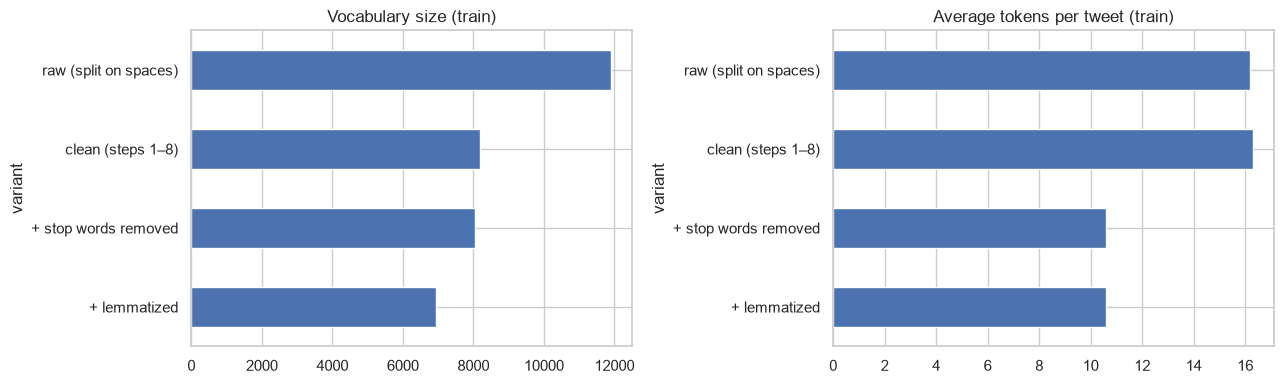

In [9]:
train = processed["train"]
VARIANTS = {"raw (split on spaces)": train.text.str.lower().str.split(),
            "clean (steps 1–8)": train.tokens,
            "+ stop words removed": train.tokens_nostop,
            "+ lemmatized": train.tokens_nostop_lemma}

rows = []
for name, toks in VARIANTS.items():
    vocab = Counter(w for ts in toks for w in ts)
    rows.append({"variant": name, "vocabulary size": len(vocab),
                 "avg tokens / tweet": round(toks.str.len().mean(), 1),
                 "empty tweets": int((toks.str.len() == 0).sum())})
summary = pd.DataFrame(rows).set_index("variant")
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
summary["vocabulary size"].plot(kind="barh", ax=ax[0], title="Vocabulary size (train)")
summary["avg tokens / tweet"].plot(kind="barh", ax=ax[1], title="Average tokens per tweet (train)")
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/variants.png", dpi=150, bbox_inches="tight"); plt.show()

In [10]:
# Are the emotion signals still there? Top tokens per emotion after full preprocessing
# (pronouns, negations and ! ? are kept in the data but hidden here, as they appear in every emotion)
HIDE = NEGATIONS | PRONOUNS | KEEP_PUNCT
top = {e: [w for w, _ in Counter(w for ts in train[train.emotion == e].tokens_nostop_lemma
                                   for w in ts if w not in HIDE).most_common(12)]
       for e in LABELS}
pd.DataFrame(top)

,anger,joy,optimism,sadness
0,get,get,sparkle,sad
1,like,love,fear,get
2,people,face_with_tears_of_joy,worry,like
3,fuck,day,get,depression
4,go,like,good,go
5,u,go,go,feel
6,say,hilarious,optimism,sadness
7,make,happy,make,lose
8,angry,look,start,depress
9,would,lol,life,see


In [11]:
# Tweets that become empty can not be classified; show them if any
for p, d in processed.items():
    empty = d[d.tokens_nostop_lemma.str.len() == 0]
    print(f"{p}: {len(empty)} empty after full preprocessing")
    for t in empty.text.head(5):
        print("   •", t)

train: 0 empty after full preprocessing
validation: 0 empty after full preprocessing
test: 0 empty after full preprocessing


## Save the processed data
Tokens are saved as space-separated strings (easy to read back with `.str.split()`).

| Column | Content | Use |
|---|---|---|
| `text` | original tweet | reference / error analysis |
| `label`, `emotion` | target | |
| `clean_text` | steps 1–8 | main input |
| `clean_nostop` | + stop words removed | variant |
| `clean_nostop_lemma` | + lemmatized | variant |

In [12]:
for p, d in processed.items():
    out = d[["text", "label", "emotion"]].copy()
    out["clean_text"] = d.tokens.str.join(" ")
    out["clean_nostop"] = d.tokens_nostop.str.join(" ")
    out["clean_nostop_lemma"] = d.tokens_nostop_lemma.str.join(" ")
    out.to_csv(f"{OUT_DIR}/{p}.csv", index=False)
    print(f"saved {OUT_DIR}/{p}.csv  ({len(out)} rows)")

saved ../data/processed/train.csv  (3232 rows)
saved ../data/processed/validation.csv  (374 rows)
saved ../data/processed/test.csv  (1421 rows)


## Summary

| Result | Value |
|---|---|
| Duplicates removed (train) | 25 → train has **3,232** tweets (validation 374, test 1,421 unchanged) |
| Vocabulary (train) | raw **11,907** → clean **8,173** → no stop words **8,045** → lemmatized **6,926** (−42%) |
| Avg tokens / tweet | clean **16.3** → after stop-word removal **10.6** |
| Empty tweets after preprocessing | **0** in every part |

**Observations**
- Cleaning (steps 1–8) removes most of the noise: the vocabulary shrinks by 31% (`@user`, `&amp;`, `\n`, punctuation and numbers are gone).
- Stop-word removal cuts tweet length by about a third but barely changes the vocabulary: stop words are few but very frequent.
- Lemmatization merges word forms (*crying, cried* → *cry*) and shrinks the vocabulary by another 14%.
- Emotion signals survive: after preprocessing, the most frequent tokens are still emotion words (*angry, fuck* · *love, hilarious, face_with_tears_of_joy* · *fear, worry, optimism* · *sad, depression, feel*).

**Known limitations** (can be mentioned in the report)
- Slang and abbreviations are not normalised (*u* → *you*, *lol*).
- POS tagging on short, informal tweets is not always correct, so some words are not lemmatized (e.g. *worried*).
- Hashtags written in lowercase (`#noclue`) cannot be split into words.

**Next step:** `03_representation.ipynb` reads `data/processed/*.csv` and turns `clean_text` / `clean_nostop` / `clean_nostop_lemma` into numbers (BoW, TF-IDF, word embeddings).
Note for embeddings: emoji tokens like `loudly_crying_face` can be split on `_` to look up their words.